In [1]:
import numpy as np
import matplotlib.pyplot as plt
import meshio

Warning: Unknown index 4. Skipping.

Warning: Zone specification not supported yet (interior, interior-surface_body). Skipping.

Warning: Zone specification not supported yet (fluid, surface_body). Skipping.

Warning: Zone specification not supported yet (pressure-outlet, outlet). Skipping.

Warning: Zone specification not supported yet (wall, wall1). Skipping.

Warning: Zone specification not supported yet (wall, wall2). Skipping.

Warning: Zone specification not supported yet (wall, wall3). Skipping.

Warning: Zone specification not supported yet (velocity-inlet, inlet). Skipping.

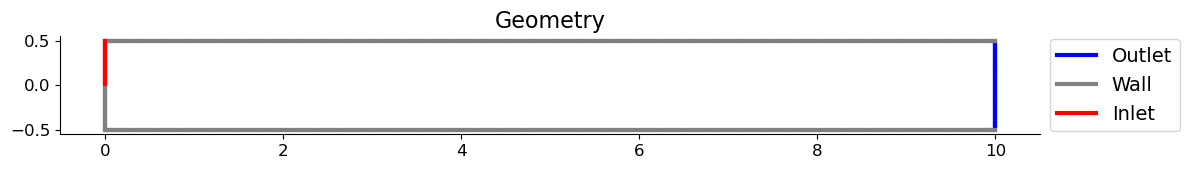

In [2]:
mesh = meshio.read(r"Input/mesh.msh")
points = mesh.points[:, :2]

plt.figure(figsize=(12, 2))

colors = plt.cm.tab10(np.linspace(0, 1, len(mesh.cells)))

wall_labeled = False

for i, cell_block in enumerate(mesh.cells):
    if i == 0:
        continue
    
    if cell_block.type == "line":
        lines = cell_block.data
        
        if i in [2, 3, 4]:
            color = 'gray'
            label_text = "Wall" if not wall_labeled else None
        elif i == 1:
            color = 'blue'
            label_text = "Outlet"
        elif i == 5:
            color = 'red' 
            label_text = "Inlet"
        else:
            color = colors[i]
            label_text = f"Line block {i}"
        
        for j, line in enumerate(lines):
            p1 = points[line[0]]
            p2 = points[line[1]]

            if j == 0 and label_text is not None:
                plt.plot([p1[0], p2[0]], [p1[1], p2[1]],
                         color=color, linewidth=3,
                         label=label_text)
                if i in [2, 3, 4]:
                    wall_labeled = True
            else:
                plt.plot([p1[0], p2[0]], [p1[1], p2[1]],
                         color=color, linewidth=3)

ax = plt.gca()
ax.set_aspect("equal")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=14)
plt.title("Geometry", fontsize=16)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.tight_layout()
plt.savefig("Input/mesh_geometry.png", dpi=300, bbox_inches='tight', pad_inches=0)
plt.show()